In [149]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import linregress

# Task 2.2

---

In [150]:
def linear(x, a, b):
    return a * x + b

In [151]:
files = ["task2.2.1_small_light.xls", "task2.2.1_small.xls", "task2.2.1_large_light.xls", "task2.2.1_large.xls"]

# linear middle part of the forward curve (roughly -2 V ... -1 V, I ~ 2-12 mA)
fit_windows = {
    "task2.2.1_small_light.xls": slice(29, 40),   # -2.1 ... -1.1 V
    "task2.2.1_small.xls":       slice(30, 41),   # -2.0 ... -1.0 V
    "task2.2.1_large_light.xls": slice(28, 40),   # -2.2 ... -1.1 V
    "task2.2.1_large.xls":       slice(31, 41),   # -1.9 ... -1.0 V
}

resistances = []
for file in files:
    path = "../data/" + file

    df = pd.read_excel(path)

    df_numpy = df.to_numpy().T

    df_lin = df_numpy[0 : 2]
    
    reg = linregress(df_lin[0, fit_windows[file]], df_lin[1, fit_windows[file]])
    resistances.append(1/ reg[0])

print(resistances)


[np.float64(117.52297097427429), np.float64(127.83060154186767), np.float64(126.65494258305935), np.float64(126.73553085144546)]


In [152]:
# threshold voltage: x-intercept of the linear fit, V_th = -b/a
thresholds = []
for file in files:
    df = pd.read_excel("../data/" + file)
    V, I = df["V_Pos"].to_numpy(), df["I_Pos"].to_numpy()
    s = fit_windows[file]
    reg = linregress(V[s], I[s])
    a, b = reg.slope, reg.intercept

    V_th = -b / a
    
    thresholds.append(V_th)
    print(f"{file:28s} V_th = {V_th:.3f} V")


task2.2.1_small_light.xls    V_th = -0.692 V
task2.2.1_small.xls          V_th = -0.721 V
task2.2.1_large_light.xls    V_th = -0.656 V
task2.2.1_large.xls          V_th = -0.702 V


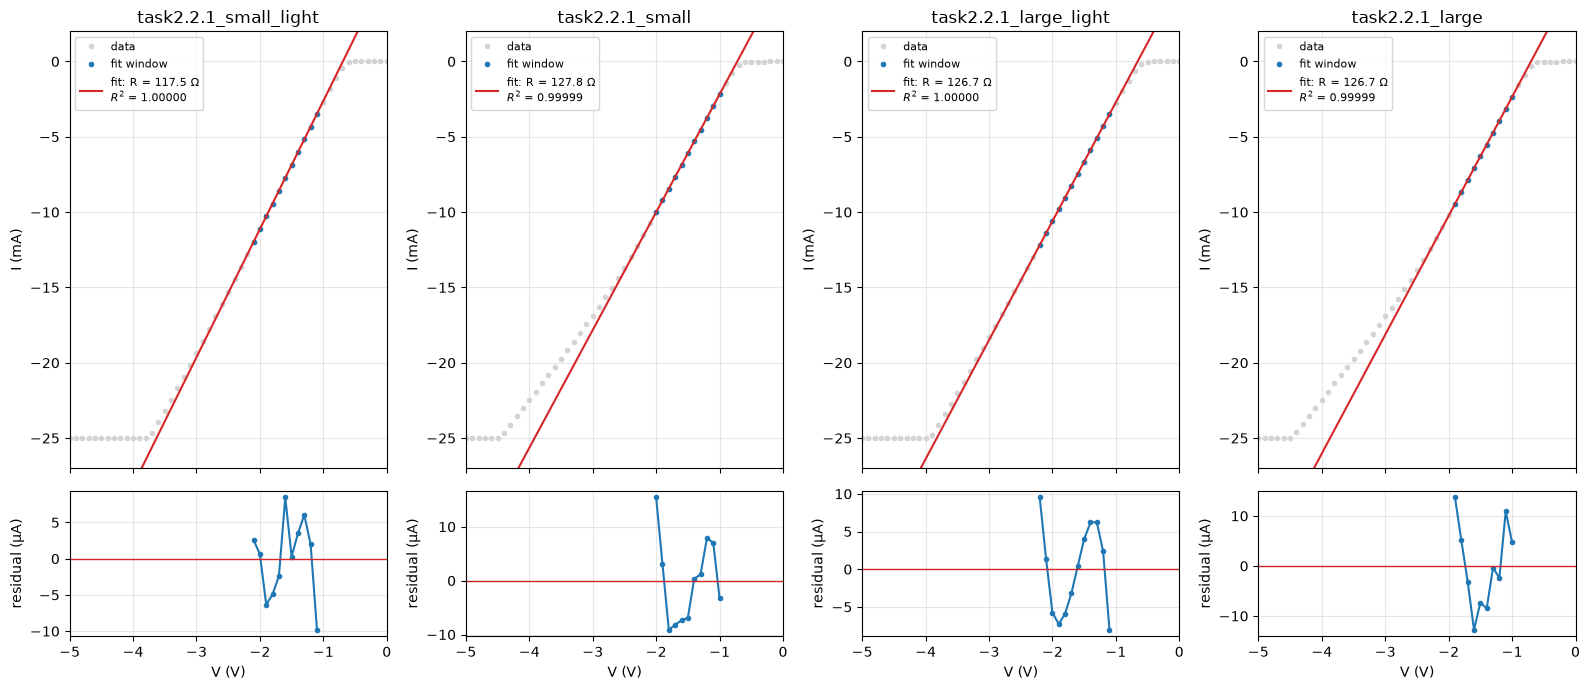

In [153]:
# Check plots: data + regression (top), residuals of the fit window (bottom)
fig, axes = plt.subplots(2, len(files), figsize=(4 * len(files), 7),
                         sharex="col", gridspec_kw={"height_ratios": [3, 1]})

for k, file in enumerate(files):
    df = pd.read_excel("../data/" + file)
    V, I = df["V_Pos"].to_numpy(), df["I_Pos"].to_numpy()

    fit_slice = fit_windows[file]   # same windows as above
    reg = linregress(V[fit_slice], I[fit_slice])
    V_fit, I_fit = V[fit_slice], I[fit_slice]

    ax, ax_res = axes[0, k], axes[1, k]

    # data and fit
    ax.plot(V, I * 1e3, ".", color="lightgray", label="data")
    ax.plot(V_fit, I_fit * 1e3, ".", color="C0", label="fit window")
    V_line = np.linspace(-5, 0, 100)
    ax.plot(V_line, linear(V_line, reg.slope, reg.intercept) * 1e3, "-", color="C3",
            label=f"fit: R = {1 / reg.slope:.1f} Ω\n$R^2$ = {reg.rvalue**2:.5f}")
    ax.set_xlim(-5, 0)
    ax.set_ylim(-27, 2)
    ax.set_title(file.replace(".xls", ""))
    ax.set_ylabel("I (mA)")
    ax.legend(fontsize=8)
    ax.grid(alpha=0.3)

    # residuals inside the fit window
    res = I_fit - linear(V_fit, reg.slope, reg.intercept)
    ax_res.plot(V_fit, res * 1e6, "o-", ms=3, color="C0")
    ax_res.axhline(0, color="C3", lw=1)
    ax_res.set_xlabel("V (V)")
    ax_res.set_ylabel("residual (µA)")
    ax_res.grid(alpha=0.3)

fig.tight_layout()
plt.show()

# Task 2.4

---

In [154]:
df = pd.read_excel("../data/task2.2.7.xls")
print(df.head())

   V_Pos     I_Pos     V          I
0  -0.50 -0.000010  0.50 -11.470375
1  -0.49 -0.000010  0.49 -11.558036
2  -0.48 -0.000009  0.48 -11.635816
3  -0.47 -0.000008  0.47 -11.707147
4  -0.46 -0.000008  0.46 -11.773177


V_T = 25.69 mV
S   = 5.692 ± 0.084 1/V
n   = 6.84 ± 0.10
I_0 = 5.894e-07 A


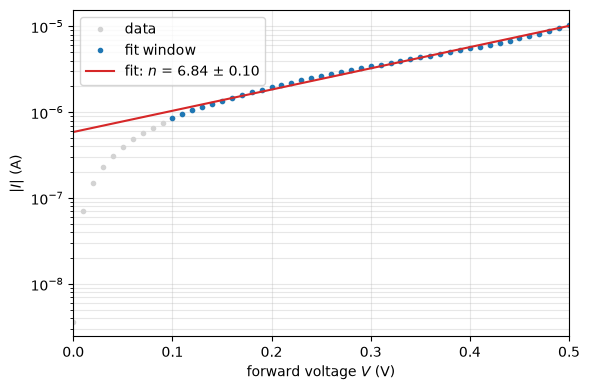

In [155]:
from scipy.constants import k as k_B, e

V_F = -df["V_Pos"].to_numpy()          # forward voltage (SMU on cathode)
I_F = np.abs(df["I_Pos"].to_numpy())   # |I| for the log scale

# thermal voltage
T = 298.15                              # K
V_T = k_B * T / e                       # ~25.7 mV

# fit ln(I) = ln(I_0) + V / (n V_T) in the exponential part
fit_slice = slice(0, 41)                # data runs 0.5 V -> 0 V, so this is 0.50 ... 0.21 V
reg_n = linregress(V_F[fit_slice], np.log(I_F[fit_slice]))

S = reg_n.slope                         # 1/V
n = 1 / (S * V_T)
n_err = n * reg_n.stderr / S
I_0 = np.exp(reg_n.intercept)

print(f"V_T = {V_T * 1e3:.2f} mV")
print(f"S   = {S:.3f} ± {reg_n.stderr:.3f} 1/V")
print(f"n   = {n:.2f} ± {n_err:.2f}")
print(f"I_0 = {I_0:.3e} A")

# plot
fig, ax = plt.subplots(figsize=(6, 4))
ax.semilogy(V_F, I_F, ".", color="lightgray", label="data")
ax.semilogy(V_F[fit_slice], I_F[fit_slice], ".", color="C0", label="fit window")
V_line = np.linspace(0, 0.5, 100)
ax.semilogy(V_line, I_0 * np.exp(V_line / (n * V_T)), "-", color="C3",
            label=rf"fit: $n$ = {n:.2f} $\pm$ {n_err:.2f}")
ax.set_xlabel(r"forward voltage $V$ (V)")
ax.set_ylabel(r"$|I|$ (A)")
ax.set_xlim(0, 0.5)
ax.legend()
ax.grid(alpha=0.3, which="both")
fig.tight_layout()
plt.show()